# 第 6 章配套 Notebook：脉冲神经元：IF/LIF 方程、复位对比、0.3 核心手算表与浮点容差陷阱

[![Open In Colab (main)](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/main/notion/notebooks/ch06_spiking_neurons.ipynb) （PR 审查期分支链接：[点此在 Colab 打开 gemini/deep-02 版](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/gemini/deep-02/notion/notebooks/ch06_spiking_neurons.ipynb)）

> **运行环境**：仅需 Python ≥ 3.10、`numpy`、`matplotlib`，不需要 GPU，也不依赖 PyTorch 等深度学习框架。所有矩阵每一步的中间数值均直接打印并与第 6 章正文手算结果逐位核对一致。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# 配置中文与负号显示（Windows / Linux / macOS / Colab 通用回退）
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'Arial Unicode MS', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
np.set_printoptions(precision=6, suppress=True)
print("NumPy version:", np.__version__)


NumPy version: 2.5.5


## 1. 置零复位（Hard Reset）vs 减法复位（Soft Reset）逐步对照表

复现第 6 章例 6.1（对应 Rueckauer 等 2017 Section 2 Eq. 4a–6）：设恒定输入电流 $z = 0.6$，阈值 $\theta = 1.0$，初值 $v[0] = 0$，运行 $T = 10$ 步：
- **置零复位**（发放后强行归零 $v[t] = v^-[t](1 - s[t])$）：每次在 $v^-=1.2$ 发放时白白扔掉 $0.2$ 的超额电量，10 步只发 **5** 个脉冲（发放率 $0.50 \neq 0.60$，永久低估 $0.10$）！
- **减法复位**（发放后减去一个阈值 $v[t] = v^-[t] - \theta s[t]$）：保留余量 $0.2$ 留给下一步，10 步刚好发 **6** 个脉冲（发放率 $0.60$，零误差）！

In [2]:
from fractions import Fraction

def run_if_exact(z_frac: Fraction, theta_frac: Fraction, T: int, reset_mode: str = "sub"):
    v = Fraction(0, 1)
    rows = []
    for t in range(1, T + 1):
        v_minus = v + z_frac
        s = 1 if v_minus >= theta_frac else 0
        if reset_mode == "zero":
            v = Fraction(0, 1) if s == 1 else v_minus
        elif reset_mode == "sub":
            v = v_minus - theta_frac * s
        else:
            raise ValueError(reset_mode)
        rows.append((t, float(v_minus), s, float(v)))
    return rows

z06 = Fraction(6, 10)
th1 = Fraction(1, 1)
rows_zero = run_if_exact(z06, th1, T=10, reset_mode="zero")
rows_sub  = run_if_exact(z06, th1, T=10, reset_mode="sub")

print("t  | [置零复位] v^-[t]  s[t]  v[t] | [减法复位] v^-[t]  s[t]  v[t]")
print("---+-------------------------------+------------------------------")
for r_z, r_s in zip(rows_zero, rows_sub):
    print(f"{r_z[0]:2d} |           {r_z[1]:5.2f}     {r_z[2]}   {r_z[3]:5.2f} |           {r_s[1]:5.2f}     {r_s[2]}   {r_s[3]:5.2f}")

rate_zero = sum(r[2] for r in rows_zero) / 10
rate_sub  = sum(r[2] for r in rows_sub) / 10
print(f"\n置零复位总脉冲 = {sum(r[2] for r in rows_zero)}, 发放率 r = {rate_zero:.2f} (理论偏低误差 = {0.6 - rate_zero:.2f})")
print(f"减法复位总脉冲 = {sum(r[2] for r in rows_sub)}, 发放率 r = {rate_sub:.2f} (精确匹配 z/theta = 0.60)")
assert sum(r[2] for r in rows_zero) == 5
assert sum(r[2] for r in rows_sub) == 6


t  | [置零复位] v^-[t]  s[t]  v[t] | [减法复位] v^-[t]  s[t]  v[t]
---+-------------------------------+------------------------------
 1 |            0.60     0    0.60 |            0.60     0    0.60
 2 |            1.20     1    0.00 |            1.20     1    0.20
 3 |            0.60     0    0.60 |            0.80     0    0.80
 4 |            1.20     1    0.00 |            1.40     1    0.40
 5 |            0.60     0    0.60 |            1.00     1    0.00
 6 |            1.20     1    0.00 |            0.60     0    0.60
 7 |            0.60     0    0.60 |            1.20     1    0.20
 8 |            1.20     1    0.00 |            0.80     0    0.80
 9 |            0.60     0    0.60 |            1.40     1    0.40
10 |            1.20     1    0.00 |            1.00     1    0.00

置零复位总脉冲 = 5, 发放率 r = 0.50 (理论偏低误差 = 0.10)
减法复位总脉冲 = 6, 发放率 r = 0.60 (精确匹配 z/theta = 0.60)


## 2. 核心手算表（验收标准第 2 条）与 IEEE-754 浮点数 `0.9999999999999998` 陷阱

给定恒定输入 $z = 0.3$、阈值 $\theta = 1$、初始膜电位 $v[0] = 0$、总步数 $T = 10$（减法复位）：
1. **精确十进制算术（`Fraction(3, 10)`）**：第 4 步（$1.2 \to 0.2$）、第 7 步（$1.1 \to 0.1$）、第 10 步（$1.0 \to 0.0$）各发放 1 次，**共 3 个脉冲，发放率 $r = 3/10 = 0.3$**。
2. **Python 双精度浮点数（`float64`）不加容差**：因为十进制 `0.3` 在二进制浮点里无法精确表示（实际存的是 `0.29999999999999998890...`），累加与减法复位到第 10 步时，充电后膜电位算出的是 **`0.9999999999999998 < 1.0`**，差了 $2.22 \times 10^{-16}$，导致第 10 步漏掉脉冲，**只得到 2 个脉冲（发放率跌成 `0.2`）**！
3. **加上微小数值容差 `eps = 1e-9`（判定 `v_minus >= theta - 1e-9`）**：消除二进制舍入毛刺，恢复精确的 **3 个脉冲（`r = 0.3`）**。这也是任务 02 第 1 页 F5 互动动画专门加上 `1e-9` 容差的原因！

In [3]:
# 1) 精确有理数手算核对
exact_03 = run_if_exact(Fraction(3, 10), Fraction(1, 1), T=10, reset_mode="sub")

# 2) 原生 Python / NumPy float64 不加容差
v_f64 = 0.0
z_f64 = 0.3
theta_f64 = 1.0
float_no_tol = []
for t in range(1, 11):
    v_minus = v_f64 + z_f64
    s = 1 if v_minus >= theta_f64 else 0
    v_f64 = v_minus - theta_f64 * s
    float_no_tol.append((t, v_minus, s, v_f64))

# 3) float64 加上 eps = 1e-9 容差
v_tol = 0.0
eps_tol = 1e-9
float_with_tol = []
for t in range(1, 11):
    v_minus = v_tol + z_f64
    s = 1 if v_minus >= (theta_f64 - eps_tol) else 0
    v_tol = v_minus - theta_f64 * s
    float_with_tol.append((t, v_minus, s, v_tol))

print("t  | [精确算术] v^-  s   v   | [float64 无容差] v^-[t] (17位有效数字)   s  v[t]                  | [加 1e-9 容差] s")
print("---+-------------------------+-------------------------------------------------------------------+-----------------")
for ex, fl, ft in zip(exact_03, float_no_tol, float_with_tol):
    print(f"{ex[0]:2d} |          {ex[1]:4.1f}   {ex[2]}  {ex[3]:4.1f} |   {fl[1]:.17f}   {fl[2]}  {fl[3]:.17f} |        {ft[2]}")

spikes_exact = [r[0] for r in exact_03 if r[2] == 1]
spikes_notol = [r[0] for r in float_no_tol if r[2] == 1]
spikes_tol   = [r[0] for r in float_with_tol if r[2] == 1]

print(f"\n精确算术脉冲时刻     : {spikes_exact} -> 共 {len(spikes_exact)} 次, 发放率 r = {len(spikes_exact)/10:.1f}")
print(f"float64 无容差脉冲时刻: {spikes_notol}     -> 共 {len(spikes_notol)} 次, 发放率 r = {len(spikes_notol)/10:.1f}  (t=10 时 v^- = {float_no_tol[-1][1]!r} < 1.0！)")
print(f"float64 加 1e-9 容差 : {spikes_tol} -> 共 {len(spikes_tol)} 次, 发放率 r = {len(spikes_tol)/10:.1f}")

assert spikes_exact == [4, 7, 10]
assert spikes_notol == [4, 7] and repr(float_no_tol[-1][1]) == "0.9999999999999998"
assert spikes_tol == [4, 7, 10]


t  | [精确算术] v^-  s   v   | [float64 无容差] v^-[t] (17位有效数字)   s  v[t]                  | [加 1e-9 容差] s
---+-------------------------+-------------------------------------------------------------------+-----------------
 1 |           0.3   0   0.3 |   0.29999999999999999   0  0.29999999999999999 |        0
 2 |           0.6   0   0.6 |   0.59999999999999998   0  0.59999999999999998 |        0
 3 |           0.9   0   0.9 |   0.89999999999999991   0  0.89999999999999991 |        0
 4 |           1.2   1   0.2 |   1.19999999999999996   1  0.19999999999999996 |        1
 5 |           0.5   0   0.5 |   0.49999999999999994   0  0.49999999999999994 |        0
 6 |           0.8   0   0.8 |   0.79999999999999993   0  0.79999999999999993 |        0
 7 |           1.1   1   0.1 |   1.09999999999999987   1  0.09999999999999987 |        1
 8 |           0.4   0   0.4 |   0.39999999999999986   0  0.39999999999999986 |        0
 9 |           0.7   0   0.7 |   0.69999999999999984   0  0.69999999999

## 3. IF（无漏电 $\beta=1$）vs LIF（漏电衰减 $\beta < 1$）：为什么免训练转换偏爱 IF，直接训练偏爱 LIF？

对同一个输入 $z = 0.3, \theta = 1.0$，对比 IF（$\beta = 1.0$）、轻度漏电 LIF（$\beta = 0.8$）与强漏电 LIF（$\beta = 0.6$）：
- 当 $\beta = 0.6$ 时，即使永远不发脉冲，膜电位稳态上界也只有 $v_{\infty} = \frac{z}{1 - \beta} = \frac{0.3}{1 - 0.6} = 0.75 < \theta = 1.0$，**永远跨不过阈值（死区电流 $z_{\mathrm{th}} = (1-\beta)\theta = 0.4$）**！这破坏了与 ReLU 在 $(0, 0.4)$ 区间的正比对应关系。

IF  (beta=1.0) 10步脉冲序列: [0 0 0 1 0 0 1 0 0 1] 总脉冲: 3
LIF (beta=0.8) 10步脉冲序列: [0 0 0 0 1 0 0 0 0 1] 总脉冲: 2
LIF (beta=0.6) 10步脉冲序列: [0 0 0 0 0 0 0 0 0 0] 总脉冲: 0 (稳态上界 0.3/(1-0.6)=0.75 < 1.0，永远不发！)


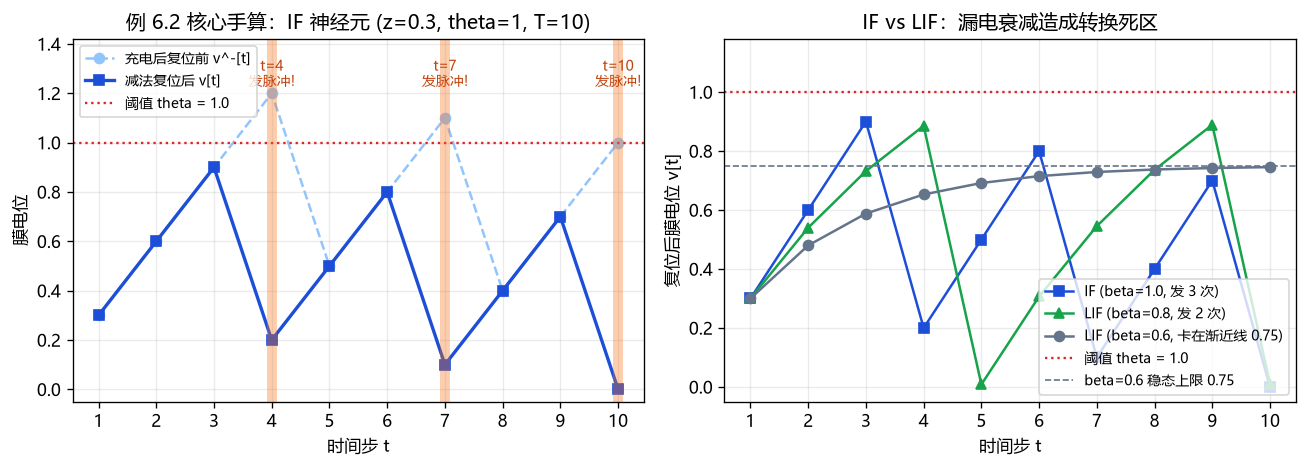

In [4]:
def run_lif(z: float, theta: float, beta: float, T: int = 15, eps: float = 1e-9):
    v = 0.0
    v_minus_hist, s_hist, v_hist = [], [], []
    for t in range(T):
        v_minus = beta * v + z
        s = 1.0 if v_minus >= theta - eps else 0.0
        v = v_minus - theta * s
        v_minus_hist.append(v_minus)
        s_hist.append(s)
        v_hist.append(v)
    return np.array(v_minus_hist), np.array(s_hist), np.array(v_hist)

T_plot = 10
steps = np.arange(1, T_plot + 1)
vm_if,  s_if,  v_if  = run_lif(0.3, 1.0, beta=1.0, T=T_plot)
vm_l8,  s_l8,  v_l8  = run_lif(0.3, 1.0, beta=0.8, T=T_plot)
vm_l6,  s_l6,  v_l6  = run_lif(0.3, 1.0, beta=0.6, T=T_plot)

print("IF  (beta=1.0) 10步脉冲序列:", s_if.astype(int), "总脉冲:", int(s_if.sum()))
print("LIF (beta=0.8) 10步脉冲序列:", s_l8.astype(int), "总脉冲:", int(s_l8.sum()))
print("LIF (beta=0.6) 10步脉冲序列:", s_l6.astype(int), "总脉冲:", int(s_l6.sum()), "(稳态上界 0.3/(1-0.6)=0.75 < 1.0，永远不发！)")
assert int(s_if.sum()) == 3 and int(s_l6.sum()) == 0

fig, axes = plt.subplots(1, 2, figsize=(11, 4.0), dpi=120)

# 左图：z=0.3 时 IF 充电前/复位后电位与脉冲时刻
ax = axes[0]
ax.plot(steps, vm_if, "o--", color="#93c5fd", label="充电后复位前 v^-[t]")
ax.plot(steps, v_if,  "s-",  color="#1d4ed8", lw=2.0, label="减法复位后 v[t]")
ax.axhline(1.0, color="#dc2626", ls=":", lw=1.4, label="阈值 theta = 1.0")
for t_idx in np.where(s_if > 0)[0]:
    ax.axvline(t_idx + 1, color="#f97316", alpha=0.35, lw=6)
    ax.text(t_idx + 1, 1.23, f"t={t_idx+1}\n发脉冲!", ha="center", fontsize=8.5, color="#c2410c")
ax.set_xticks(steps)
ax.set_ylim(-0.05, 1.42)
ax.set_xlabel("时间步 t")
ax.set_ylabel("膜电位")
ax.set_title("例 6.2 核心手算：IF 神经元 (z=0.3, theta=1, T=10)")
ax.legend(loc="upper left", fontsize=8.5)
ax.grid(True, alpha=0.25)

# 右图：IF vs LIF 膜电位轨迹对比
ax2 = axes[1]
ax2.plot(steps, v_if, "s-", color="#1d4ed8", label="IF (beta=1.0, 发 3 次)")
ax2.plot(steps, v_l8, "^-", color="#16a34a", label=f"LIF (beta=0.8, 发 {int(s_l8.sum())} 次)")
ax2.plot(steps, v_l6, "o-", color="#64748b", label="LIF (beta=0.6, 卡在渐近线 0.75)")
ax2.axhline(1.0, color="#dc2626", ls=":", lw=1.4, label="阈值 theta = 1.0")
ax2.axhline(0.75, color="#64748b", ls="--", lw=1.0, label="beta=0.6 稳态上限 0.75")
ax2.set_xticks(steps)
ax2.set_ylim(-0.05, 1.18)
ax2.set_xlabel("时间步 t")
ax2.set_ylabel("复位后膜电位 v[t]")
ax2.set_title("IF vs LIF：漏电衰减造成转换死区")
ax2.legend(loc="lower right", fontsize=8.5)
ax2.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()
